# C6 · Quanto a fábrica paga a mais no horário de ponta

**Pergunta:** quanto uma indústria economiza por ano tirando carga do horário de ponta,
sem perder produção no dia?

Fontes:
- **Consumo:** *Steel Industry Energy Consumption* (UCI Machine Learning Repository) —
  consumo real de uma siderúrgica (DAEWOO Steel, Gwangyang, Coreia do Sul), de 15 em 15
  minutos, durante 2018. 35.040 registros.
- **Tarifa:** tarifa horária verde do subgrupo A4 da CEMIG, dos dados abertos da ANEEL
  (tarifas homologadas das distribuidoras), arquivo `dados/tarifa_cemig.json`.

É um exercício de método: a curva é de uma usina coreana, e a tarifa é brasileira.

## 1. A curva de carga

Cada registro é a energia consumida (kWh) nos 15 minutos que **terminam** no horário
indicado. A potência média do intervalo é kWh × 4.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv('dados/Steel_industry_data.csv')
d['fim'] = pd.to_datetime(d.date, format='%d/%m/%Y %H:%M')
d['ini'] = d.fim - pd.Timedelta(minutes=15)
d['kwh'] = d.Usage_kWh
d['dia'] = d.ini.dt.normalize()
d['hora'] = d.ini.dt.hour + d.ini.dt.minute / 60
d['util'] = d.ini.dt.dayofweek < 5
print(f"{len(d):,} intervalos · {d.ini.min():%d/%m/%Y %H:%M} a {d.ini.max():%d/%m/%Y %H:%M}")
print(f"Consumo no ano: {d.kwh.sum()/1000:,.0f} MWh · demanda máxima de 15 min: {d.kwh.max()*4:,.0f} kW")

35,040 intervalos · 31/12/2017 23:45 a 31/12/2018 23:30
Consumo no ano: 960 MWh · demanda máxima de 15 min: 629 kW


## 2. O horário de ponta

**Ponta:** 17h às 20h (17:00–19:59) nos dias úteis, o posto horário da CEMIG em contratos
públicos de uso do sistema de distribuição. Fins de semana não têm ponta. Feriados não
foram descontados (são coreanos, na curva). O posto horário vem junto com a tarifa e é
conferido no arquivo da ANEEL.

In [2]:
INI_PONTA, FIM_PONTA = 17, 20
d['ponta'] = d.util & (d.hora >= INI_PONTA) & (d.hora < FIM_PONTA)
E_TOTAL, E_PONTA = d.kwh.sum(), d[d.ponta].kwh.sum()
H_PONTA = d.ponta.mean()
print(f'Energia na ponta: {E_PONTA/1000:,.1f} MWh = {E_PONTA/E_TOTAL:.1%} do consumo, em {H_PONTA:.1%} das horas do ano')
perfil = d[d.util].groupby(d.hora.astype(int)).kwh.mean() * 4
print((perfil).round(0).astype(int).to_string())

Energia na ponta: 155.3 MWh = 16.2% do consumo, em 8.9% das horas do ano
hora
0      32
1      21
2      18
3      17
4      17
5      17
6      17
7      21
8     248
9     282
10    270
11    274
12     32
13    251
14    271
15    268
16    271
17    198
18    193
19    204
20    179
21     50
22     39
23     37


## 3. Quanto dá para tirar da ponta

**Regra do deslocamento**, dia útil a dia útil:

- uma fração *f* da energia de ponta do dia pode mudar de horário (premissa: depende de
  quais processos admitem mudança — é ela que o painel deixa ajustar);
- a energia sai da ponta e entra **no mesmo dia**, fora da ponta, nos intervalos de menor
  carga primeiro (de madrugada, no almoço);
- nenhum intervalo pode passar da **demanda máxima que a fábrica já teve no ano** — para
  não criar um pico novo e encarecer a demanda.

Não precisa de otimizador: na tarifa verde, toda hora fora de ponta custa o mesmo, então
qualquer intervalo com folga serve. A regra simples já dá o máximo.

In [3]:
TETO = d.kwh.max()          # kWh por 15 min = demanda máxima já registrada

def deslocar(f):
    movido = 0.0
    for dia, g in d[d.util].groupby('dia'):
        querer = f * g[g.ponta].kwh.sum()
        folga = (TETO - g[~g.ponta].kwh).clip(lower=0).sum()
        movido += min(querer, folga)
    return movido

FRACOES = [0, .05, .10, .15, .20, .25, .30, .40]
cen = pd.DataFrame({'fracao': FRACOES, 'mwh_movidos': [deslocar(f) / 1000 for f in FRACOES]})
cen['limitado_pela_folga'] = cen.mwh_movidos < cen.fracao * E_PONTA / 1000 - 1e-6
cen.round(2)

,fracao,mwh_movidos,limitado_pela_folga
0,0.00,0.00,False
1,0.05,7.77,False
2,0.10,15.53,False
3,0.15,23.30,False
4,0.20,31.07,False
5,0.25,38.83,False
6,0.30,46.60,False
7,0.40,62.13,False


## 4. A tarifa e o valor em reais

A tarifa horária verde cobra a energia (TUSD + TE) com preço diferente na ponta e fora
dela; a demanda contratada tem preço único. Deslocar energia da ponta para fora dela
economiza **(preço na ponta − preço fora da ponta) × kWh deslocado**. Impostos (ICMS,
PIS/Cofins) e bandeiras tarifárias ficam fora — a conta é sobre a tarifa homologada.

In [4]:
arq = Path('dados/tarifa_cemig.json')
TARIFA = json.loads(arq.read_text(encoding='utf-8')) if arq.exists() else None
if TARIFA:
    DIF = TARIFA['ponta_rs_kwh'] - TARIFA['fora_ponta_rs_kwh']
    print(f"CEMIG · A4 · horária verde · {TARIFA['resolucao']} (vigência a partir de {TARIFA['vigencia']})")
    print(f"Ponta: R$ {TARIFA['ponta_rs_kwh']:.4f}/kWh · fora de ponta: R$ {TARIFA['fora_ponta_rs_kwh']:.4f}/kWh · diferença R$ {DIF:.4f}/kWh")
    cen['economia_rs_ano'] = cen.mwh_movidos * 1000 * DIF
    CUSTO_PONTA = E_PONTA * TARIFA['ponta_rs_kwh']
    CUSTO_ENERGIA = CUSTO_PONTA + (E_TOTAL - E_PONTA) * TARIFA['fora_ponta_rs_kwh']
    PARTE_CONTA = CUSTO_PONTA / CUSTO_ENERGIA
    print(f"Conta de energia (TUSD + TE, sem demanda nem impostos): R$ {CUSTO_ENERGIA:,.0f} por ano")
    print(f"Energia da ponta: {E_PONTA/E_TOTAL:.1%} do consumo e R$ {CUSTO_PONTA:,.0f} = {PARTE_CONTA:.1%} da conta de energia")
    cen['parte_da_conta'] = cen.economia_rs_ano / CUSTO_ENERGIA
else:
    DIF = None
    print('Tarifa oficial ainda não carregada (dados/tarifa_cemig.json). A conta em reais fica pendente.')
cen.round(2)

CEMIG · A4 · horária verde · Resolução Homologatória ANEEL nº 3.589, de 26 de maio de 2026 (vigência a partir de 2026-05-28)
Ponta: R$ 2.3872/kWh · fora de ponta: R$ 0.4808/kWh · diferença R$ 1.9064/kWh
Conta de energia (TUSD + TE, sem demanda nem impostos): R$ 757,492 por ano
Energia da ponta: 16.2% do consumo e R$ 370,807 = 49.0% da conta de energia


,fracao,mwh_movidos,limitado_pela_folga,economia_rs_ano,parte_da_conta
0,0.00,0.00,False,0.00,0.00
1,0.05,7.77,False,14806.38,0.02
2,0.10,15.53,False,29612.75,0.04
3,0.15,23.30,False,44419.13,0.06
4,0.20,31.07,False,59225.50,0.08
5,0.25,38.83,False,74031.88,0.10
6,0.30,46.60,False,88838.25,0.12
7,0.40,62.13,False,118451.00,0.16


## 5. O número

In [5]:
f20 = cen.set_index('fracao').loc[.20]
print(f'{E_PONTA/E_TOTAL:.0%} da energia da fábrica cai nas 3 horas de ponta dos dias úteis ({H_PONTA:.0%} das horas do ano).')
print(f'Deslocando 20% da carga de ponta para outros horários do mesmo dia: {f20.mwh_movidos:,.1f} MWh por ano saem da ponta.')
if DIF is not None:
    print(f'Na tarifa verde A4 da CEMIG, essas 3 horas respondem por {PARTE_CONTA:.0%} da conta de energia.')
    print(f'Deslocar 20% da carga de ponta economiza R$ {f20.economia_rs_ano:,.0f} por ano = {f20.parte_da_conta:.1%} da conta de energia.')

16% da energia da fábrica cai nas 3 horas de ponta dos dias úteis (9% das horas do ano).
Deslocando 20% da carga de ponta para outros horários do mesmo dia: 31.1 MWh por ano saem da ponta.
Na tarifa verde A4 da CEMIG, essas 3 horas respondem por 49% da conta de energia.
Deslocar 20% da carga de ponta economiza R$ 59,226 por ano = 7.8% da conta de energia.


## 6. Capa

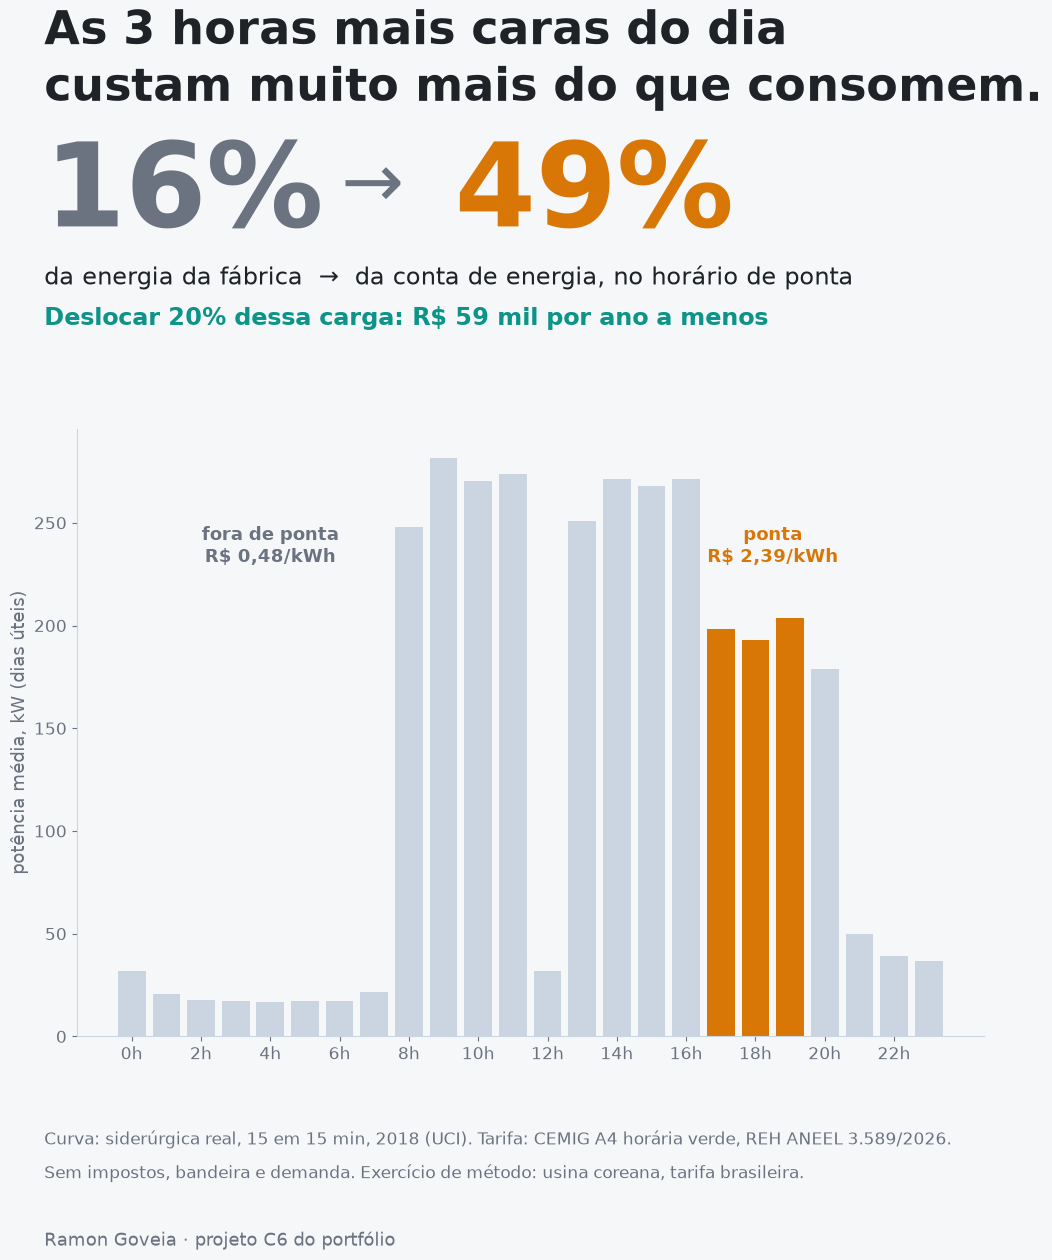

In [6]:
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['text.parse_math'] = False
# paleta do C6: grafite, âmbar para a hora cara (ponta), verde-petróleo para a economia
TINTA, AMBAR, PETROLEO, CINZA, CLARO = '#1f2328', '#d97706', '#0d9488', '#6b7280', '#cbd5e1'
virg = lambda v, d=0: f'{v:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
fig = plt.figure(figsize=(10.8, 13.5), dpi=100); fig.patch.set_facecolor('#f6f7f9')
fig.text(.07, .935, 'As 3 horas mais caras do dia', fontsize=33, weight='bold', color=TINTA)
fig.text(.07, .893, 'custam muito mais do que consomem.', fontsize=33, weight='bold', color=TINTA)
fig.text(.07, .80, f'{E_PONTA/E_TOTAL:.0%}', fontsize=84, weight='bold', color=CINZA)
fig.text(.345, .815, '→', fontsize=54, color=CINZA)
fig.text(.45, .80, f'{PARTE_CONTA:.0%}', fontsize=84, weight='bold', color=AMBAR)
fig.text(.07, .757, 'da energia da fábrica  →  da conta de energia, no horário de ponta', fontsize=17, color=TINTA)
fig.text(.07, .727, f'Deslocar 20% dessa carga: R$ {virg(f20.economia_rs_ano/1000)} mil por ano a menos', fontsize=17, color=PETROLEO, weight='bold')
ax = fig.add_axes([.1, .2, .84, .45]); ax.set_facecolor('#f6f7f9')
cores = [AMBAR if INI_PONTA <= h < FIM_PONTA else CLARO for h in perfil.index]
ax.bar(perfil.index, perfil.values, color=cores, width=.8)
ax.set_xticks(range(0, 24, 2), [f'{h}h' for h in range(0, 24, 2)])
ax.set_ylabel('potência média, kW (dias úteis)', fontsize=13, color=CINZA)
ax.tick_params(colors=CINZA, labelsize=12)
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
for sp in ['left', 'bottom']: ax.spines[sp].set_color(CLARO)
ax.text(18.5, perfil.max() * .82, 'ponta\n' + f'R$ {virg(TARIFA["ponta_rs_kwh"], 2)}/kWh', ha='center', fontsize=13, color=AMBAR, weight='bold')
ax.text(4, perfil.max() * .82, 'fora de ponta\n' + f'R$ {virg(TARIFA["fora_ponta_rs_kwh"], 2)}/kWh', ha='center', fontsize=13, color=CINZA, weight='bold')
fig.text(.07, .12, 'Curva: siderúrgica real, 15 em 15 min, 2018 (UCI). Tarifa: CEMIG A4 horária verde, REH ANEEL 3.589/2026.', fontsize=12, color=CINZA)
fig.text(.07, .095, 'Sem impostos, bandeira e demanda. Exercício de método: usina coreana, tarifa brasileira.', fontsize=12, color=CINZA)
fig.text(.07, .045, 'Ramon Goveia · projeto C6 do portfólio', fontsize=13, color=CINZA)
fig.savefig('capa.png', dpi=100, facecolor='#f6f7f9'); plt.show()

## 7. Dados do painel

In [7]:
Path('painel').mkdir(exist_ok=True)
dias = sorted(d.dia.unique())
exp = {'inicio': str(d.ini.min()), 'teto_kwh': round(float(TETO), 2), 'ponta': [INI_PONTA, FIM_PONTA],
       'kwh': [round(float(v), 2) for v in d.sort_values('ini').kwh], 'tarifa': TARIFA,
       'resumo': {'parte_conta': round(float(PARTE_CONTA), 4), 'e_total_mwh': round(float(E_TOTAL) / 1000, 1), 'e_ponta_mwh': round(float(E_PONTA) / 1000, 1),
                  'parte_ponta': round(float(E_PONTA / E_TOTAL), 4), 'horas_ponta': round(float(H_PONTA), 4)}}
Path('painel/dados.js').write_text('window.ENERGIA = ' + json.dumps(exp, ensure_ascii=False, separators=(',', ':')) + ';\n', encoding='utf-8')
print(f"painel/dados.js · {Path('painel/dados.js').stat().st_size/1e3:.0f} KB")

painel/dados.js · 188 KB


## 8. Limitações

- **Usina coreana, tarifa brasileira.** A curva é de uma siderúrgica na Coreia do Sul em
  2018; o horário de ponta e a tarifa são da CEMIG. É um exercício de método: a mesma conta
  vale para a curva de carga de qualquer fábrica brasileira no grupo A.
- **A fração deslocável é premissa.** Nem todo processo muda de horário: forno contínuo não
  para, turno extra tem custo de pessoal (adicional noturno), e mudar a produção pode mexer
  em estoque e prazo. A economia é bruta — não desconta esses custos.
- **Sem impostos e sem bandeira tarifária.** ICMS, PIS/Cofins e bandeiras aumentam a conta
  total e a diferença em reais; a análise usa só a tarifa homologada.
- **Só a tarifa verde, só energia.** Na verde, a demanda tem preço único — deslocar energia
  não muda a demanda, desde que não crie pico novo (por isso o teto). Na tarifa azul, a
  demanda de ponta também é cobrada à parte; fica para o D5.
- **Feriados não descontados** e um único ano de curva.